# Classificação de ELA a partir de sinais eletromiográficos (EMG)

**Objetivo:** Investigar a classificação de janelas de EMG de pessoas com esclerose lateral amiotrófica (ELA) e controles saudáveis, comparando uma **CNN espectral independente** com uma **CNN espectral com fusão de cinco descritores** (RMS, ZCR, WL, SSC e MF).

**Dados:** EMGLAB N2001. A divisão é feita **por paciente**, antes de criar janelas, para impedir que janelas do mesmo indivíduo apareçam em conjuntos diferentes. Classes: `0 = controle`; `1 = ELA`.

**Limitação:** O conjunto contém poucos pacientes independentes. As métricas por janela não representam o mesmo número de observações independentes.

## 1. Ambiente e carregamento dos dados

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import zipfile
import re

from pathlib import Path

SEED = 42
np.random.seed(SEED)

In [2]:
!pip -q install wfdb

In [3]:
from google.colab import files

uploaded = files.upload()

Saving archive (1).zip to archive (1).zip


In [4]:
pasta_dados = Path("/content/dataset_ela_n2001")
pasta_dados.mkdir(parents=True, exist_ok=True)

arquivo_zip = next(
    nome for nome in uploaded
    if nome.lower().endswith(".zip")
)

with zipfile.ZipFile(arquivo_zip, "r") as z:
    z.extractall(pasta_dados)

arquivos_bin = sorted(pasta_dados.rglob("*.bin"))
arquivos_hea = sorted(pasta_dados.rglob("*.hea"))

print("Arquivos .bin:", len(arquivos_bin))
print("Arquivos .hea:", len(arquivos_hea))
print("Total:", len(arquivos_bin) + len(arquivos_hea))

Arquivos .bin: 475
Arquivos .hea: 475
Total: 950


## 2. Indexação dos registros e definição das classes

In [5]:
registros = []

for arquivo in arquivos_hea:

    nome = arquivo.stem

    identificacao = re.match(
        r"N2001([ACM]\d{2})",
        nome
    )

    if identificacao is None:
        continue

    paciente = identificacao.group(1)

    conteudo = arquivo.read_text(
        encoding="latin-1"
    )

    diagnostico = re.search(
        r"#diagnosis:\s*(.+)",
        conteudo,
        flags=re.IGNORECASE
    )

    diagnostico = (
        diagnostico.group(1).strip()
        if diagnostico else "Desconhecido"
    )

    registros.append({
        "registro": nome,
        "paciente": paciente,
        "grupo": paciente[0],
        "diagnostico": diagnostico,
        "arquivo_hea": str(arquivo),
        "arquivo_bin": str(arquivo.with_suffix(".bin"))
    })

df = pd.DataFrame(registros)

print("Total de registros:", len(df))
print("Total de pacientes:", df["paciente"].nunique())

display(df.head())

Total de registros: 475
Total de pacientes: 22


,registro,paciente,grupo,diagnostico,arquivo_hea,arquivo_bin
0,N2001A01BB01,A01,A,ALS,/content/dataset_ela_n2001/N2001A01BB01.hea,/content/dataset_ela_n2001/N2001A01BB01.bin
1,N2001A01BB02,A01,A,ALS,/content/dataset_ela_n2001/N2001A01BB02.hea,/content/dataset_ela_n2001/N2001A01BB02.bin
2,N2001A01BB03,A01,A,ALS,/content/dataset_ela_n2001/N2001A01BB03.hea,/content/dataset_ela_n2001/N2001A01BB03.bin
3,N2001A01BB04,A01,A,ALS,/content/dataset_ela_n2001/N2001A01BB04.hea,/content/dataset_ela_n2001/N2001A01BB04.bin
4,N2001A01BB05,A01,A,ALS,/content/dataset_ela_n2001/N2001A01BB05.hea,/content/dataset_ela_n2001/N2001A01BB05.bin


In [6]:
resumo = df.groupby("grupo").agg(
    pacientes=("paciente", "nunique"),
    registros=("registro", "count")
)

print("Distribuição por grupo:")
display(resumo)

print("\nRegistros por paciente:")
display(
    df.groupby(["grupo", "paciente"])
      .size()
      .reset_index(name="quantidade_registros")
)

Distribuição por grupo:


,pacientes,registros
grupo,,
A,7,98
C,9,270
M,6,107



Registros por paciente:


,grupo,paciente,quantidade_registros
0,A,A01,12
1,A,A03,20
2,A,A04,20
3,A,A05,3
4,A,A06,18
5,A,A07,10
6,A,A08,15
7,C,C01,30
8,C,C02,30
9,C,C03,30


In [7]:
df_binario = df[
    df["grupo"].isin(["A", "C"])
].copy()

df_binario["rotulo"] = (
    df_binario["grupo"] == "A"
).astype(int)

print("Total de registros:", len(df_binario))
print("Total de pacientes:",
      df_binario["paciente"].nunique())

print("\nDistribuição das classes:")
print(df_binario["rotulo"].value_counts())

print("\nMapeamento:")
print("0 = Controle saudável")
print("1 = ELA")

Total de registros: 368
Total de pacientes: 16

Distribuição das classes:
rotulo
0    270
1     98
Name: count, dtype: int64

Mapeamento:
0 = Controle saudável
1 = ELA


## 3. Divisão por paciente

In [8]:
import numpy as np

rng = np.random.default_rng(42)

# Identificar os pacientes de cada classe
pacientes_ela = np.array(sorted(
    df_binario.loc[
        df_binario["rotulo"] == 1, "paciente"
    ].unique()
))

pacientes_controle = np.array(sorted(
    df_binario.loc[
        df_binario["rotulo"] == 0, "paciente"
    ].unique()
))

# Embaralhar os identificadores de forma reproduzível
rng.shuffle(pacientes_ela)
rng.shuffle(pacientes_controle)

# Treinamento
pacientes_treino = list(pacientes_ela[:4]) + \
                   list(pacientes_controle[:5])

# Validação
pacientes_validacao = list(pacientes_ela[4:5]) + \
                      list(pacientes_controle[5:7])

# Teste
pacientes_teste = list(pacientes_ela[5:]) + \
                  list(pacientes_controle[7:])

print("Pacientes de treinamento:", pacientes_treino)
print("Pacientes de validação:", pacientes_validacao)
print("Pacientes de teste:", pacientes_teste)

Pacientes de treinamento: [np.str_('A05'), np.str_('A04'), np.str_('A08'), np.str_('A06'), np.str_('C07'), np.str_('C08'), np.str_('C03'), np.str_('C04'), np.str_('C01')]
Pacientes de validação: [np.str_('A03'), np.str_('C02'), np.str_('C09')]
Pacientes de teste: [np.str_('A07'), np.str_('A01'), np.str_('C05'), np.str_('C06')]


In [9]:
treino = set(pacientes_treino)
validacao = set(pacientes_validacao)
teste = set(pacientes_teste)

assert treino.isdisjoint(validacao), \
    "Vazamento entre treinamento e validação!"

assert treino.isdisjoint(teste), \
    "Vazamento entre treinamento e teste!"

assert validacao.isdisjoint(teste), \
    "Vazamento entre validação e teste!"

assert treino | validacao | teste == \
       set(df_binario["paciente"].unique()), \
       "Existem pacientes ausentes da divisão!"

print("Verificação concluída!")
print("Nenhum paciente aparece em mais de um conjunto")

Verificação concluída!
Nenhum paciente aparece em mais de um conjunto


In [10]:
df_treino = df_binario[
    df_binario["paciente"].isin(pacientes_treino)
].copy()

df_validacao = df_binario[
    df_binario["paciente"].isin(pacientes_validacao)
].copy()

df_teste = df_binario[
    df_binario["paciente"].isin(pacientes_teste)
].copy()

def mostrar_resumo(nome, dados):
    print(f"\n=== {nome} ===")
    print("Pacientes:", dados["paciente"].nunique())
    print("Registros:", len(dados))
    print("ELA:", (dados["rotulo"] == 1).sum())
    print("Controle:", (dados["rotulo"] == 0).sum())

mostrar_resumo("TREINAMENTO", df_treino)
mostrar_resumo("VALIDAÇÃO", df_validacao)
mostrar_resumo("TESTE", df_teste)

assert (
    len(df_treino) +
    len(df_validacao) +
    len(df_teste)
) == len(df_binario)

assert set(df_treino["registro"]).isdisjoint(
    set(df_validacao["registro"]) |
    set(df_teste["registro"])
)

print("\nTodos os registros foram distribuídos sem sobreposição.")


=== TREINAMENTO ===
Pacientes: 9
Registros: 206
ELA: 56
Controle: 150

=== VALIDAÇÃO ===
Pacientes: 3
Registros: 80
ELA: 20
Controle: 60

=== TESTE ===
Pacientes: 4
Registros: 82
ELA: 22
Controle: 60

Todos os registros foram distribuídos sem sobreposição.


## 4. Qualidade dos registros e segmentação

In [11]:
import wfdb
import numpy as np
import pandas as pd
from pathlib import Path

resultados_integridade = []

for _, linha in df_binario.iterrows():

    caminho = str(
        Path(linha["arquivo_hea"]).with_suffix("")
    )

    try:
        registro = wfdb.rdrecord(caminho)
        sinal_atual = registro.p_signal[:, 0]

        resultados_integridade.append({
            "paciente": linha["paciente"],
            "registro": linha["registro"],
            "rotulo": linha["rotulo"],
            "amostras": len(sinal_atual),
            "frequencia": registro.fs,
            "duracao": len(sinal_atual) / registro.fs,
            "valores_invalidos": int(
                np.sum(~np.isfinite(sinal_atual))
            ),
            "status": "OK"
        })

    except Exception as erro:
        resultados_integridade.append({
            "paciente": linha["paciente"],
            "registro": linha["registro"],
            "rotulo": linha["rotulo"],
            "amostras": np.nan,
            "frequencia": np.nan,
            "duracao": np.nan,
            "valores_invalidos": np.nan,
            "status": f"ERRO: {erro}"
        })

df_integridade = pd.DataFrame(resultados_integridade)

print("Total de registros:", len(df_integridade))

print("\nStatus dos arquivos:")
print(df_integridade["status"].value_counts())

print("\nFrequências de amostragem:")
print(df_integridade["frequencia"].value_counts())

print("\nResumo das durações:")
display(df_integridade["duracao"].describe())

print("\nRegistros com problemas:")
display(
    df_integridade[
        df_integridade["status"] != "OK"
    ]
)

Total de registros: 368

Status dos arquivos:
status
OK    368
Name: count, dtype: int64

Frequências de amostragem:
frequencia
23437.5    368
Name: count, dtype: int64

Resumo das durações:


,duracao
count,3.680000e+02
mean,1.118396e+01
std,6.047836e-14
min,1.118396e+01
25%,1.118396e+01
50%,1.118396e+01
75%,1.118396e+01
max,1.118396e+01



Registros com problemas:


,paciente,registro,rotulo,amostras,frequencia,duracao,valores_invalidos,status


In [12]:
# Identificar quais registros apresentam valores inválidos
registros_invalidos = df_integridade[
    df_integridade["valores_invalidos"] > 0
].copy()

print("Registros afetados:", len(registros_invalidos))
print("Total de valores inválidos:",
      int(registros_invalidos["valores_invalidos"].sum()))

print("\nRegistros com mais valores inválidos:")
display(
    registros_invalidos[
        ["paciente", "registro", "valores_invalidos"]
    ].sort_values(
        "valores_invalidos", ascending=False
    ).head(15)
)

print("\nDistribuição por grupo:")
display(
    registros_invalidos.assign(
        grupo=registros_invalidos["paciente"].str[0]
    ).groupby("grupo").agg(
        registros_afetados=("registro", "count"),
        valores_invalidos=("valores_invalidos", "sum")
    )
)

print("\nTipos de valores inválidos:")
print("Vamos verificar NaN e infinito na próxima célula.")

Registros afetados: 19
Total de valores inválidos: 41763

Registros com mais valores inválidos:


,paciente,registro,valores_invalidos
247,C05,N2001C05BB80,16848
16,A03,N2001A03BB55,13405
66,A06,N2001A06BB12,8058
61,A06,N2001A06BB07,3047
83,A08,N2001A08BB01,33
85,A08,N2001A08BB03,33
84,A08,N2001A08BB02,33
87,A08,N2001A08BB05,33
88,A08,N2001A08BB06,33
89,A08,N2001A08BB07,33



Distribuição por grupo:


,registros_afetados,valores_invalidos
grupo,,
A,18,24915
C,1,16848



Tipos de valores inválidos:
Vamos verificar NaN e infinito na próxima célula.


In [13]:
import wfdb
import numpy as np
import pandas as pd
from pathlib import Path

FS = 23437.5
DURACAO_JANELA = 1.0

def segmentar_registros(df_registros):

    janelas = []
    metadados = []
    descartadas = []

    for _, linha in df_registros.iterrows():

        caminho = str(
            Path(linha["arquivo_hea"]).with_suffix("")
        )

        registro = wfdb.rdrecord(caminho)
        sinal = registro.p_signal[:, 0]
        fs = registro.fs

        numero_janelas = int(
            len(sinal) / fs / DURACAO_JANELA
        )

        for indice in range(numero_janelas):

            inicio = round(indice * DURACAO_JANELA * fs)
            fim = round((indice + 1) * DURACAO_JANELA * fs)

            janela = sinal[inicio:fim]

            # Verificar se a janela possui NaN ou infinito
            if not np.isfinite(janela).all():

                descartadas.append({
                    "paciente": linha["paciente"],
                    "registro": linha["registro"],
                    "janela": indice,
                    "rotulo": linha["rotulo"]
                })

                continue

            janelas.append(janela)

            metadados.append({
                "paciente": linha["paciente"],
                "registro": linha["registro"],
                "rotulo": linha["rotulo"],
                "janela": indice,
                "inicio_amostra": inicio,
                "fim_amostra": fim
            })

    return (
        janelas,
        pd.DataFrame(metadados),
        pd.DataFrame(descartadas)
    )


janelas_treino, meta_treino, descartadas_treino = \
    segmentar_registros(df_treino)

janelas_validacao, meta_validacao, descartadas_validacao = \
    segmentar_registros(df_validacao)

janelas_teste, meta_teste, descartadas_teste = \
    segmentar_registros(df_teste)


print("=== TREINAMENTO ===")
print("Janelas válidas:", len(janelas_treino))
print("Janelas descartadas:", len(descartadas_treino))

print("\n=== VALIDAÇÃO ===")
print("Janelas válidas:", len(janelas_validacao))
print("Janelas descartadas:", len(descartadas_validacao))

print("\n=== TESTE ===")
print("Janelas válidas:", len(janelas_teste))
print("Janelas descartadas:", len(descartadas_teste))

print("\nTOTAL DE JANELAS VÁLIDAS:",
      len(janelas_treino) +
      len(janelas_validacao) +
      len(janelas_teste))

=== TREINAMENTO ===
Janelas válidas: 2247
Janelas descartadas: 19

=== VALIDAÇÃO ===
Janelas válidas: 874
Janelas descartadas: 6

=== TESTE ===
Janelas válidas: 901
Janelas descartadas: 1

TOTAL DE JANELAS VÁLIDAS: 4022


In [14]:
ids_treino = set(meta_treino["paciente"])
ids_validacao = set(meta_validacao["paciente"])
ids_teste = set(meta_teste["paciente"])

assert ids_treino.isdisjoint(ids_validacao)
assert ids_treino.isdisjoint(ids_teste)
assert ids_validacao.isdisjoint(ids_teste)

assert all(np.isfinite(j).all() for j in janelas_treino)
assert all(np.isfinite(j).all() for j in janelas_validacao)
assert all(np.isfinite(j).all() for j in janelas_teste)

print("Separação por paciente preservada!")
print("Todas as janelas selecionadas possuem valores válidos.")

print("\nDistribuição das classes:")

for nome, meta in [
    ("Treinamento", meta_treino),
    ("Validação", meta_validacao),
    ("Teste", meta_teste)
]:
    print(f"\n{nome}:")
    print(meta["rotulo"].value_counts().sort_index())

Separação por paciente preservada!
Todas as janelas selecionadas possuem valores válidos.

Distribuição das classes:

Treinamento:
rotulo
0    1650
1     597
Name: count, dtype: int64

Validação:
rotulo
0    660
1    214
Name: count, dtype: int64

Teste:
rotulo
0    659
1    242
Name: count, dtype: int64


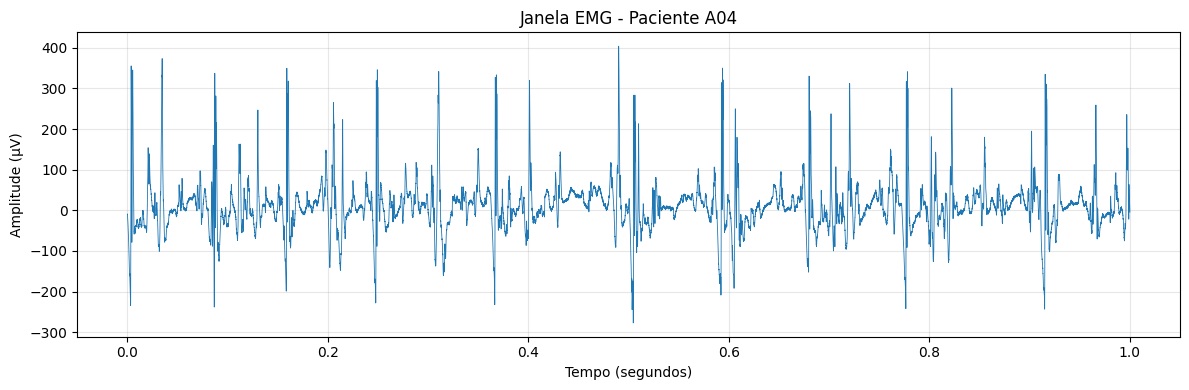

In [15]:
janela_exemplo = janelas_treino[0]

tempo = np.arange(len(janela_exemplo)) / FS

plt.figure(figsize=(12, 4))
plt.plot(tempo, janela_exemplo, linewidth=0.6)

plt.title(
    "Janela EMG - "
    f"Paciente {meta_treino.iloc[0]['paciente']}"
)

plt.xlabel("Tempo (segundos)")
plt.ylabel("Amplitude (µV)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Extração dos descritores EMG

Para cada janela extração de: **RMS** (amplitude eficaz), **ZCR** (proporção de cruzamentos por zero), **WL** (comprimento acumulado da forma de onda), **SSC** (mudanças de sinal da inclinação) e **MF** (frequência média ponderada pela potência espectral). Esses cinco atributos entram somente no ramo estatístico da arquitetura de fusão.

In [16]:
from scipy import signal
import numpy as np

def extrair_caracteristicas(janela, fs=23437.5):

    x = np.asarray(janela, dtype=np.float64)

    # 1. Root Mean Square
    rms = np.sqrt(np.mean(x ** 2))

    # 2. Zero Crossing Rate
    zcr = np.mean(x[:-1] * x[1:] < 0)

    # 3. Waveform Length
    wl = np.sum(np.abs(np.diff(x)))

    # 4. Slope Sign Changes
    diferencas = np.diff(x)
    ssc = np.sum(
        diferencas[:-1] * diferencas[1:] < 0
    )

    # 5. Mean Frequency
    frequencias, potencia = signal.welch(
        x,
        fs=fs,
        nperseg=1024
    )

    mf = np.sum(frequencias * potencia) / (
        np.sum(potencia) + 1e-10
    )

    return [rms, zcr, wl, ssc, mf]


print("Função de extração criada!")

Função de extração criada!


In [17]:
import pandas as pd

nomes_caracteristicas = [
    "RMS", "ZCR", "WL", "SSC", "MF"
]

def criar_tabela_caracteristicas(janelas, metadados):

    caracteristicas = [
        extrair_caracteristicas(janela)
        for janela in janelas
    ]

    tabela = pd.DataFrame(
        caracteristicas,
        columns=nomes_caracteristicas
    )

    tabela = pd.concat(
        [
            metadados.reset_index(drop=True),
            tabela
        ],
        axis=1
    )

    return tabela


dados_treino = criar_tabela_caracteristicas(
    janelas_treino, meta_treino
)

dados_validacao = criar_tabela_caracteristicas(
    janelas_validacao, meta_validacao
)

dados_teste = criar_tabela_caracteristicas(
    janelas_teste, meta_teste
)

print("Treinamento:", dados_treino.shape)
print("Validação:", dados_validacao.shape)
print("Teste:", dados_teste.shape)

display(dados_treino.head())

Treinamento: (2247, 11)
Validação: (874, 11)
Teste: (901, 11)


,paciente,registro,rotulo,janela,inicio_amostra,fim_amostra,RMS,ZCR,WL,SSC,MF
0,A04,N2001A04BB51,1,0,0,23438,64.171923,0.023382,79950.713359,9880,270.054999
1,A04,N2001A04BB51,1,1,23438,46875,62.082167,0.023425,79502.708476,9783,277.860321
2,A04,N2001A04BB51,1,2,46875,70312,65.194300,0.024108,82243.457694,9495,267.722378
3,A04,N2001A04BB51,1,3,70312,93750,59.081303,0.021334,74865.644312,10386,268.750245
4,A04,N2001A04BB51,1,4,93750,117188,61.606032,0.030038,79219.653620,9816,271.453969


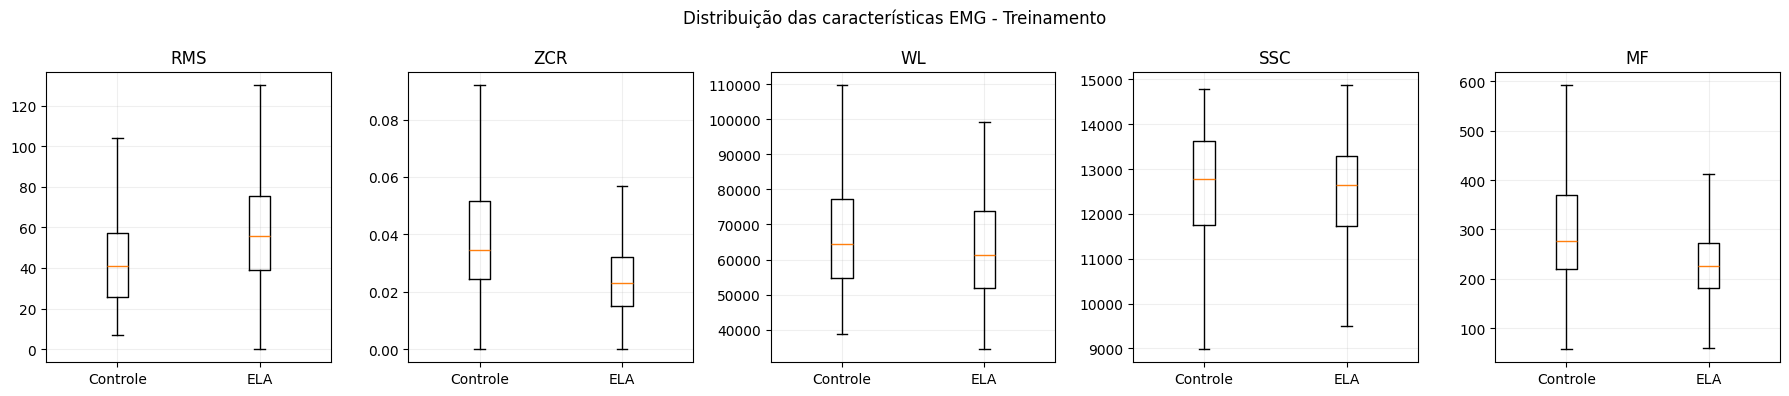

In [18]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    1, 5, figsize=(18, 4)
)

for i, caracteristica in enumerate(nomes_caracteristicas):

    controle = dados_treino.loc[
        dados_treino["rotulo"] == 0,
        caracteristica
    ]

    ela = dados_treino.loc[
        dados_treino["rotulo"] == 1,
        caracteristica
    ]

    axes[i].boxplot(
        [controle, ela],
        tick_labels=["Controle", "ELA"],
        showfliers=False
    )

    axes[i].set_title(caracteristica)
    axes[i].grid(alpha=0.2)

plt.suptitle(
    "Distribuição das características EMG - Treinamento"
)

plt.tight_layout()
plt.show()

In [19]:
import hashlib
import numpy as np

def calcular_hash(janela):
    dados = np.ascontiguousarray(
        janela, dtype=np.float64
    )
    return hashlib.sha256(
        dados.tobytes()
    ).hexdigest()

hashes_treino = {
    calcular_hash(j) for j in janelas_treino
}

hashes_validacao = {
    calcular_hash(j) for j in janelas_validacao
}

hashes_teste = {
    calcular_hash(j) for j in janelas_teste
}

duplicados_treino_validacao = (
    hashes_treino & hashes_validacao
)

duplicados_treino_teste = (
    hashes_treino & hashes_teste
)

duplicados_validacao_teste = (
    hashes_validacao & hashes_teste
)

print("Treino x Validação:",
      len(duplicados_treino_validacao))

print("Treino x Teste:",
      len(duplicados_treino_teste))

print("Validação x Teste:",
      len(duplicados_validacao_teste))

assert not duplicados_treino_validacao
assert not duplicados_treino_teste
assert not duplicados_validacao_teste

print("\nNenhuma janela exatamente duplicada entre os conjuntos!")

Treino x Validação: 0
Treino x Teste: 0
Validação x Teste: 0

Nenhuma janela exatamente duplicada entre os conjuntos!


In [20]:
# Selecionar somente as cinco características EMG
X_treino = dados_treino[nomes_caracteristicas].copy()
X_validacao = dados_validacao[nomes_caracteristicas].copy()
X_teste = dados_teste[nomes_caracteristicas].copy()

# Selecionar os rótulos
y_treino = dados_treino["rotulo"].to_numpy()
y_validacao = dados_validacao["rotulo"].to_numpy()
y_teste = dados_teste["rotulo"].to_numpy()

print("=== DIMENSÕES ===")
print("Treinamento:", X_treino.shape)
print("Validação:", X_validacao.shape)
print("Teste:", X_teste.shape)

print("\nCaracterísticas utilizadas:")
print(X_treino.columns.tolist())

print("\nClasses:")
print("0 = Controle")
print("1 = ELA")

=== DIMENSÕES ===
Treinamento: (2247, 5)
Validação: (874, 5)
Teste: (901, 5)

Características utilizadas:
['RMS', 'ZCR', 'WL', 'SSC', 'MF']

Classes:
0 = Controle
1 = ELA


In [21]:
from sklearn.preprocessing import StandardScaler

# Criar o padronizador
scaler = StandardScaler()

# Aprender média e desvio-padrão SOMENTE do treinamento
X_treino_scaled = scaler.fit_transform(X_treino)

# Aplicar a mesma transformação aos outros conjuntos
X_validacao_scaled = scaler.transform(X_validacao)
X_teste_scaled = scaler.transform(X_teste)

print("Padronização concluída!")

print("\nMédia das características no treinamento:")
print(np.round(X_treino_scaled.mean(axis=0), 4))

print("\nDesvio-padrão das características no treinamento:")
print(np.round(X_treino_scaled.std(axis=0), 4))

Padronização concluída!

Média das características no treinamento:
[ 0.  0. -0.  0. -0.]

Desvio-padrão das características no treinamento:
[1. 1. 1. 1. 1.]


In [22]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.array([0, 1])

pesos = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_treino
)

pesos_classes = dict(zip(classes, pesos))

print("Pesos das classes:")
print("Controle (0):", round(pesos_classes[0], 4))
print("ELA (1):", round(pesos_classes[1], 4))

Pesos das classes:
Controle (0): 0.6809
ELA (1): 1.8819


## 6. Preparação da entrada espectral

In [23]:
import tensorflow as tf
from scipy.signal import resample_poly

tf.keras.utils.set_random_seed(42)

print("TensorFlow:", tf.__version__)
print("Preparação para CNN iniciada!")

TensorFlow: 2.21.0
Preparação para CNN iniciada!


In [24]:
import numpy as np

TAMANHO_CNN = 2929

def preparar_janelas_cnn(janelas):
    sinais_processados = []

    for janela in janelas:

        # Redução com filtragem antialiasing
        sinal_reduzido = resample_poly(
            np.asarray(janela, dtype=np.float32),
            up=1,
            down=8
        )

        # Garantir comprimento fixo
        sinal_reduzido = sinal_reduzido[:TAMANHO_CNN]

        if len(sinal_reduzido) < TAMANHO_CNN:
            sinal_reduzido = np.pad(
                sinal_reduzido,
                (0, TAMANHO_CNN - len(sinal_reduzido))
            )

        sinais_processados.append(sinal_reduzido)

    return np.asarray(
        sinais_processados,
        dtype=np.float32
    )


X_cnn_treino = preparar_janelas_cnn(janelas_treino)
X_cnn_validacao = preparar_janelas_cnn(janelas_validacao)
X_cnn_teste = preparar_janelas_cnn(janelas_teste)

print("Treinamento:", X_cnn_treino.shape)
print("Validação:", X_cnn_validacao.shape)
print("Teste:", X_cnn_teste.shape)

Treinamento: (2247, 2929)
Validação: (874, 2929)
Teste: (901, 2929)


In [25]:
# Estatísticas calculadas exclusivamente no treinamento
media_cnn = float(X_cnn_treino.mean())
desvio_cnn = float(X_cnn_treino.std())

assert desvio_cnn > 0

# Aplicar a mesma transformação a todos os conjuntos
X_cnn_treino = (
    (X_cnn_treino - media_cnn) / desvio_cnn
)

X_cnn_validacao = (
    (X_cnn_validacao - media_cnn) / desvio_cnn
)

X_cnn_teste = (
    (X_cnn_teste - media_cnn) / desvio_cnn
)

# Adicionar dimensão do canal exigida pela CNN 1D
X_cnn_treino = X_cnn_treino[..., np.newaxis]
X_cnn_validacao = X_cnn_validacao[..., np.newaxis]
X_cnn_teste = X_cnn_teste[..., np.newaxis]

assert np.isfinite(X_cnn_treino).all()
assert np.isfinite(X_cnn_validacao).all()
assert np.isfinite(X_cnn_teste).all()

print("Entradas preparadas!")
print("Treino:", X_cnn_treino.shape)
print("Validação:", X_cnn_validacao.shape)
print("Teste:", X_cnn_teste.shape)

print("\nMédia utilizada:", media_cnn)
print("Desvio-padrão utilizado:", desvio_cnn)

Entradas preparadas!
Treino: (2247, 2929, 1)
Validação: (874, 2929, 1)
Teste: (901, 2929, 1)

Média utilizada: 4.469691276550293
Desvio-padrão utilizado: 68.6407470703125


In [26]:
import numpy as np
from scipy.signal import stft

# Frequência após redução por fator 8
fs_espectral = 23437.5 / 8

def criar_espectrogramas(X, fs=fs_espectral):
    espectrogramas = []

    for janela in X:
        sinal = janela[:, 0]

        frequencias, tempos, Z = stft(
            sinal,
            fs=fs,
            nperseg=128,
            noverlap=96,
            boundary=None,
            padded=False
        )

        # Magnitude em escala logarítmica
        espectro = np.log1p(np.abs(Z))

        espectrogramas.append(
            espectro.astype("float32")
        )

    return np.array(espectrogramas)[..., np.newaxis]


X_spec_treino = criar_espectrogramas(X_cnn_treino)
X_spec_validacao = criar_espectrogramas(X_cnn_validacao)

print("Treinamento:", X_spec_treino.shape)
print("Validação:", X_spec_validacao.shape)

assert len(X_spec_treino) == len(y_treino)
assert len(X_spec_validacao) == len(y_validacao)

Treinamento: (2247, 65, 88, 1)
Validação: (874, 65, 88, 1)


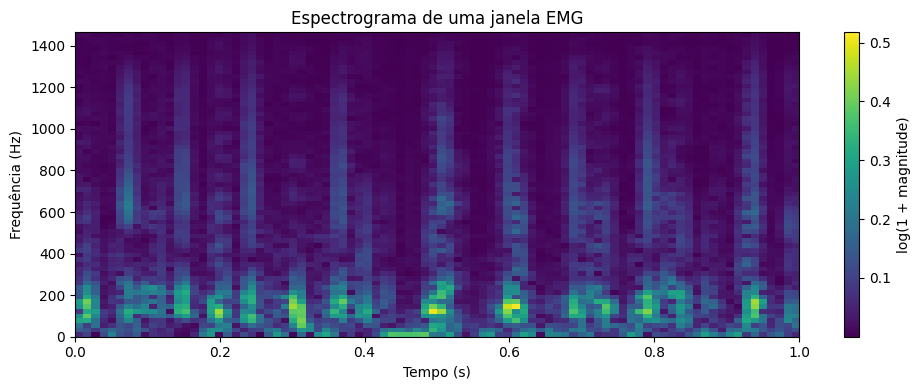

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

plt.imshow(
    X_spec_treino[0, :, :, 0],
    aspect="auto",
    origin="lower",
    extent=[0, 1, 0, fs_espectral / 2],
    cmap="viridis"
)

plt.colorbar(label="log(1 + magnitude)")
plt.xlabel("Tempo (s)")
plt.ylabel("Frequência (Hz)")
plt.title("Espectrograma de uma janela EMG")

plt.tight_layout()
plt.show()

In [28]:
import numpy as np
import tensorflow as tf

tf.keras.utils.set_random_seed(42)

assert len(X_spec_treino) == len(X_treino_scaled) == len(y_treino)
assert len(X_spec_validacao) == len(X_validacao_scaled) == len(y_validacao)

assert X_treino_scaled.shape[1] == 5
assert X_validacao_scaled.shape[1] == 5

assert np.isfinite(X_spec_treino).all()
assert np.isfinite(X_spec_validacao).all()
assert np.isfinite(X_treino_scaled).all()
assert np.isfinite(X_validacao_scaled).all()

print("Espectrogramas de treino:", X_spec_treino.shape)
print("Características de treino:", X_treino_scaled.shape)
print("Espectrogramas de validação:", X_spec_validacao.shape)
print("Características de validação:", X_validacao_scaled.shape)
print("Entradas verificadas!")

Espectrogramas de treino: (2247, 65, 88, 1)
Características de treino: (2247, 5)
Espectrogramas de validação: (874, 65, 88, 1)
Características de validação: (874, 5)
Entradas verificadas!


## 7. Modelo principal: CNN espectral independente

Usa convoluções, pooling, agregação global e camadas densas, com saída sigmoide para classificação binária. A perda é *binary cross-entropy*, com pesos de classe calculados no treinamento. O `EarlyStopping` restaura os pesos de menor perda de validação.

In [29]:
import tensorflow as tf

from tensorflow.keras import Model, Input
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D,
    GlobalAveragePooling2D,
    Dense, Dropout
)
from tensorflow.keras.optimizers import Adam

tf.keras.utils.set_random_seed(42)

entrada = Input(
    shape=X_spec_treino.shape[1:],
    name="espectrograma"
)

x = Conv2D(
    16, (3, 3),
    activation="relu",
    padding="same"
)(entrada)

x = MaxPooling2D((2, 2))(x)

x = Conv2D(
    32, (3, 3),
    activation="relu",
    padding="same"
)(x)

x = MaxPooling2D((2, 2))(x)

x = Conv2D(
    64, (3, 3),
    activation="relu",
    padding="same"
)(x)

x = GlobalAveragePooling2D()(x)

x = Dense(32, activation="relu")(x)

# Camadas de classificação
x = Dense(32, activation="relu")(x)
x = Dropout(0.3)(x)

saida = Dense(
    1,
    activation="sigmoid",
    name="classificacao"
)(x)

modelo_espectral_independente = Model(
    inputs=entrada,
    outputs=saida,
    name="CNN_Espectral_Independente"
)

modelo_espectral_independente.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc")
    ]
)

modelo_espectral_independente.summary()

Model: "CNN_Espectral_Independente"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ espectrograma (InputLayer)      │ (None, 65, 88, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 65, 88, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 44, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 44, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 22, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 22, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classificacao (Dense)           │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,465 (103.38 KB)

 Trainable params: 26,465 (103.38 KB)

 Non-trainable params: 0 (0.00 B)

In [30]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

callbacks_independente = [
    EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-5
    )
]

historico_independente = modelo_espectral_independente.fit(
    X_spec_treino,
    y_treino,

    validation_data=(
        X_spec_validacao,
        y_validacao
    ),

    epochs=40,
    batch_size=32,
    class_weight=pesos_classes,
    callbacks=callbacks_independente,
    verbose=1
)

print(
    "Épocas executadas:",
    len(historico_independente.history["loss"])
)

print(
    "Menor perda de validação:",
    min(historico_independente.history["val_loss"])
)

Epoch 1/40
71/71 ━━━━━━━━━━━━━━━━━━━━ 9s 107ms/step - accuracy: 0.4450 - auc: 0.5812 - loss: 0.6911 - val_accuracy: 0.7288 - val_auc: 0.8743 - val_loss: 0.6790 - learning_rate: 0.0010
Epoch 2/40
71/71 ━━━━━━━━━━━━━━━━━━━━ 10s 103ms/step - accuracy: 0.6337 - auc: 0.6702 - loss: 0.6605 - val_accuracy: 0.8169 - val_auc: 0.9226 - val_loss: 0.5802 - learning_rate: 0.0010
Epoch 3/40
71/71 ━━━━━━━━━━━━━━━━━━━━ 7s 102ms/step - accuracy: 0.7419 - auc: 0.7655 - loss: 0.5890 - val_accuracy: 0.8844 - val_auc: 0.9630 - val_loss: 0.3868 - learning_rate: 0.0010
Epoch 4/40
71/71 ━━━━━━━━━━━━━━━━━━━━ 8s 112ms/step - accuracy: 0.7592 - auc: 0.7990 - loss: 0.5513 - val_accuracy: 0.8661 - val_auc: 0.9735 - val_loss: 0.3980 - learning_rate: 0.0010
Epoch 5/40
71/71 ━━━━━━━━━━━━━━━━━━━━ 11s 123ms/step - accuracy: 0.7664 - auc: 0.8082 - loss: 0.5368 - val_accuracy: 0.8249 - val_auc: 0.9722 - val_loss: 0.4406 - learning_rate: 0.0010
Epoch 6/40
71/71 ━━━━━━━━━━━━━━━━━━━━ 7s 102ms/step - accuracy: 0.7810 - auc: 

### 7.1 Curvas de treinamento da CNN independente

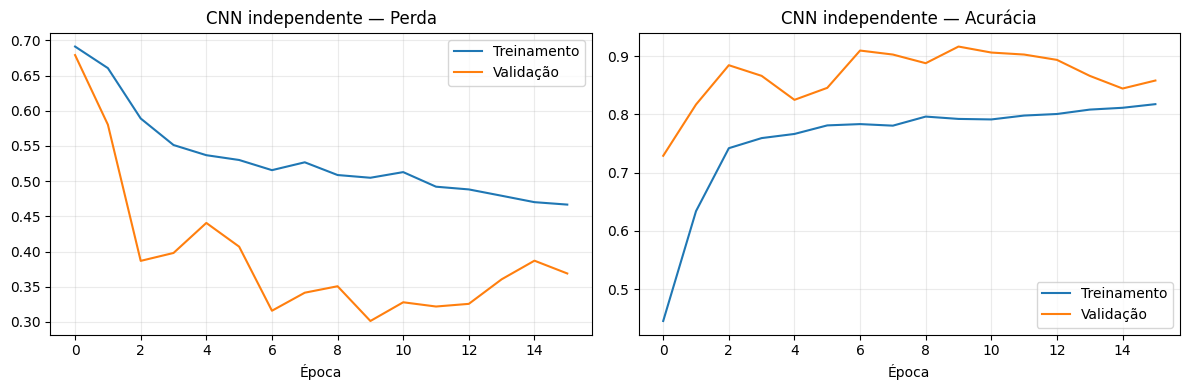

In [31]:
h = historico_independente.history
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for chave, titulo, ax in [("loss", "Perda", axes[0]), ("accuracy", "Acurácia", axes[1])]:
    ax.plot(h[chave], label="Treinamento")
    ax.plot(h["val_" + chave], label="Validação")
    ax.set_title(f"CNN independente — {titulo}")
    ax.set_xlabel("Época")
    ax.legend()
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### 7.2 Métricas e matriz de confusão na validação

=== CNN ESPECTRAL INDEPENDENTE ===
Acurácia: 0.9165
Acurácia balanceada: 0.9273
Precisão: 0.7660
Sensibilidade: 0.9486
F1-score: 0.8476
AUROC: 0.9801
AUPRC: 0.9421


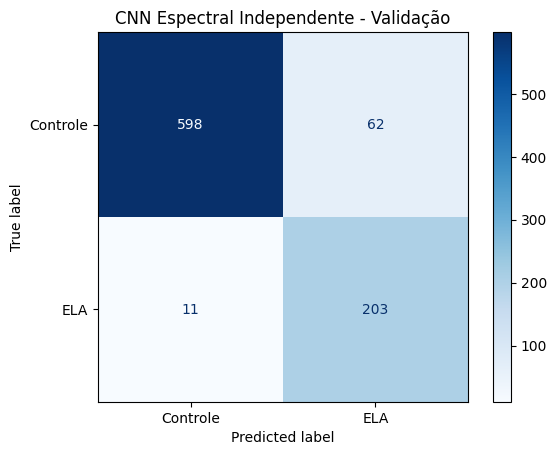

In [33]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt
import pandas as pd

prob_independente = modelo_espectral_independente.predict(
    X_spec_validacao,
    verbose=0
).ravel()

pred_independente = (
    prob_independente >= 0.5
).astype(int)

metricas_independente = {
    "Acurácia": accuracy_score(
        y_validacao, pred_independente
    ),
    "Acurácia balanceada": balanced_accuracy_score(
        y_validacao, pred_independente
    ),
    "Precisão": precision_score(
        y_validacao, pred_independente,
        zero_division=0
    ),
    "Sensibilidade": recall_score(
        y_validacao, pred_independente,
        zero_division=0
    ),
    "F1-score": f1_score(
        y_validacao, pred_independente,
        zero_division=0
    ),
    "AUROC": roc_auc_score(
        y_validacao, prob_independente
    ),
    "AUPRC": average_precision_score(
        y_validacao, prob_independente
    )
}

print("=== CNN ESPECTRAL INDEPENDENTE ===")

for metrica, valor in metricas_independente.items():
    print(f"{metrica}: {valor:.4f}")

ConfusionMatrixDisplay.from_predictions(
    y_validacao,
    pred_independente,
    display_labels=["Controle", "ELA"],
    cmap="Blues",
    values_format="d"
)

plt.title("CNN Espectral Independente - Validação")
plt.show()

## 8. Modelo comparativo: CNN espectral + descritores EMG

Um segundo ramo (MLP) recebe os cinco descritores padronizados; sua representação é concatenada à representação aprendida pela CNN espectral. O treinamento é realizado do zero. Esta comparação é **exploratória**: a cabeça classificadora e a quantidade de parâmetros não são rigorosamente idênticas entre os modelos, portanto não isola causalmente o efeito dos descritores.

In [34]:
from tensorflow.keras import Model, Input
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D, GlobalAveragePooling2D,
    Dense, Dropout, Concatenate
)
from tensorflow.keras.optimizers import Adam

# Entrada 1: espectrograma
entrada_spec = Input(
    shape=X_spec_treino.shape[1:],
    name="entrada_espectrograma"
)

# Ramo espectral
s = Conv2D(
    16, (3, 3), activation="relu", padding="same"
)(entrada_spec)

s = MaxPooling2D((2, 2))(s)

s = Conv2D(
    32, (3, 3), activation="relu", padding="same"
)(s)

s = MaxPooling2D((2, 2))(s)

s = Conv2D(
    64, (3, 3), activation="relu", padding="same"
)(s)

s = GlobalAveragePooling2D()(s)

s = Dense(32, activation="relu")(s)


# Entrada 2: cinco características EMG
entrada_features = Input(
    shape=(5,),
    name="entrada_caracteristicas"
)

# Ramo estatístico
f = Dense(16, activation="relu")(entrada_features)
f = Dense(8, activation="relu")(f)


# Fusão das representações
fusao = Concatenate(name="fusao_caracteristicas")(
    [s, f]
)

z = Dense(32, activation="relu")(fusao)
z = Dropout(0.3)(z)

saida = Dense(
    1,
    activation="sigmoid",
    name="classificacao_ela"
)(z)


modelo_espectral_fusao = Model(
    inputs=[entrada_spec, entrada_features],
    outputs=saida,
    name="CNN_Espectral_Fusao"
)

modelo_espectral_fusao.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc")
    ]
)

modelo_espectral_fusao.summary()

Model: "CNN_Espectral_Fusao"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ entrada_espectrogr… │ (None, 65, 88, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 65, 88,    │        160 │ entrada_espectro… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 32, 44,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 32, 44,    │      4,640 │ max_pooling2d_2[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 16, 22,    │          0 │ conv2d_4[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 16, 22,    │     18,496 │ max_pooling2d_3[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ entrada_caracteris… │ (None, 5)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ conv2d_5[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 16)        │         96 │ entrada_caracter… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 32)        │      2,080 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 8)         │        136 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusao_caracteristi… │ (None, 40)        │          0 │ dense_2[0][0],    │
│ (Concatenate)       │                   │            │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 32)        │      1,312 │ fusao_caracteris… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 32)        │          0 │ dense_5[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ classificacao_ela   │ (None, 1)         │         33 │ dropout_1[0][0]   │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 26,953 (105.29 KB)

 Trainable params: 26,953 (105.29 KB)

 Non-trainable params: 0 (0.00 B)

In [36]:
entradas_fusao_treino = {
    "entrada_espectrograma": X_spec_treino.astype("float32"),
    "entrada_caracteristicas": X_treino_scaled.astype("float32")
}

entradas_fusao_validacao = {
    "entrada_espectrograma": X_spec_validacao.astype("float32"),
    "entrada_caracteristicas": X_validacao_scaled.astype("float32")
}

print("Entradas de treino preparadas!")
print("Espectrogramas:", entradas_fusao_treino["entrada_espectrograma"].shape)
print("Descritores:", entradas_fusao_treino["entrada_caracteristicas"].shape)

Entradas de treino preparadas!
Espectrogramas: (2247, 65, 88, 1)
Descritores: (2247, 5)


In [37]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

callbacks_fusao_espectral = [
    EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-5
    )
]

historico_espectral_fusao = modelo_espectral_fusao.fit(
    entradas_fusao_treino,
    y_treino,

    validation_data=(
        entradas_fusao_validacao,
        y_validacao
    ),

    epochs=40,
    batch_size=32,
    class_weight=pesos_classes,
    callbacks=callbacks_fusao_espectral,
    verbose=1
)

print(
    "Épocas executadas:",
    len(historico_espectral_fusao.history["loss"])
)

print(
    "Menor perda de validação:",
    min(historico_espectral_fusao.history["val_loss"])
)

Epoch 1/40
71/71 ━━━━━━━━━━━━━━━━━━━━ 9s 107ms/step - accuracy: 0.6306 - auc: 0.6358 - loss: 0.6852 - val_accuracy: 0.5423 - val_auc: 0.6652 - val_loss: 0.6755 - learning_rate: 0.0010
Epoch 2/40
71/71 ━━━━━━━━━━━━━━━━━━━━ 7s 94ms/step - accuracy: 0.6538 - auc: 0.7270 - loss: 0.6282 - val_accuracy: 0.5526 - val_auc: 0.7078 - val_loss: 0.6908 - learning_rate: 0.0010
Epoch 3/40
71/71 ━━━━━━━━━━━━━━━━━━━━ 7s 103ms/step - accuracy: 0.6925 - auc: 0.7892 - loss: 0.5677 - val_accuracy: 0.5629 - val_auc: 0.8755 - val_loss: 0.7141 - learning_rate: 0.0010
Epoch 4/40
71/71 ━━━━━━━━━━━━━━━━━━━━ 7s 94ms/step - accuracy: 0.7583 - auc: 0.8414 - loss: 0.5063 - val_accuracy: 0.6419 - val_auc: 0.9278 - val_loss: 0.5791 - learning_rate: 0.0010
Epoch 5/40
71/71 ━━━━━━━━━━━━━━━━━━━━ 11s 102ms/step - accuracy: 0.7891 - auc: 0.8674 - loss: 0.4703 - val_accuracy: 0.6579 - val_auc: 0.9350 - val_loss: 0.5443 - learning_rate: 0.0010
Epoch 6/40
71/71 ━━━━━━━━━━━━━━━━━━━━ 8s 111ms/step - accuracy: 0.8060 - auc: 0.8

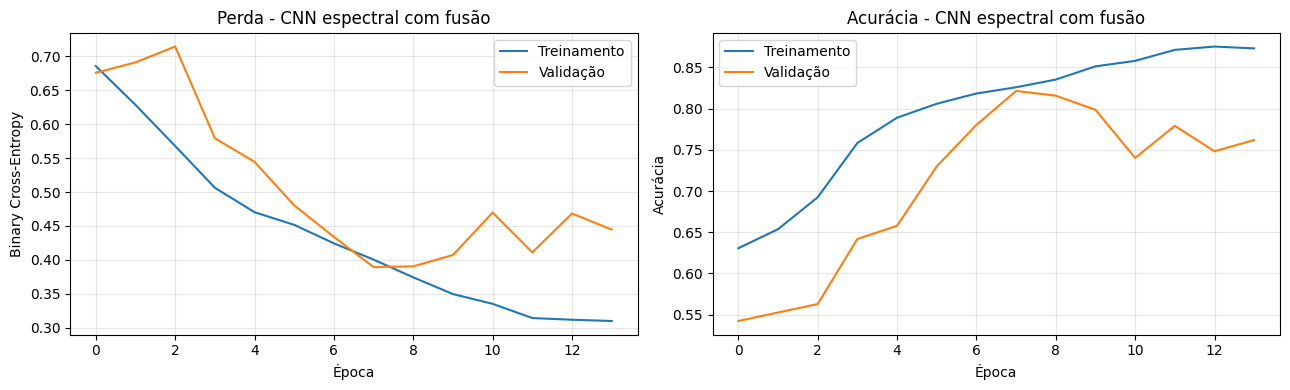

In [38]:
import matplotlib.pyplot as plt

h = historico_espectral_fusao.history

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(h["loss"], label="Treinamento")
axes[0].plot(h["val_loss"], label="Validação")
axes[0].set_title("Perda - CNN espectral com fusão")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Binary Cross-Entropy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(h["accuracy"], label="Treinamento")
axes[1].plot(h["val_accuracy"], label="Validação")
axes[1].set_title("Acurácia - CNN espectral com fusão")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Acurácia")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

=== CNN ESPECTRAL COM FUSÃO — VALIDAÇÃO ===
Acurácia: 0.8215
Acurácia balanceada: 0.8755
Precisão: 0.5801
Sensibilidade: 0.9813
F1-score: 0.7292
AUROC: 0.9718
AUPRC: 0.9323


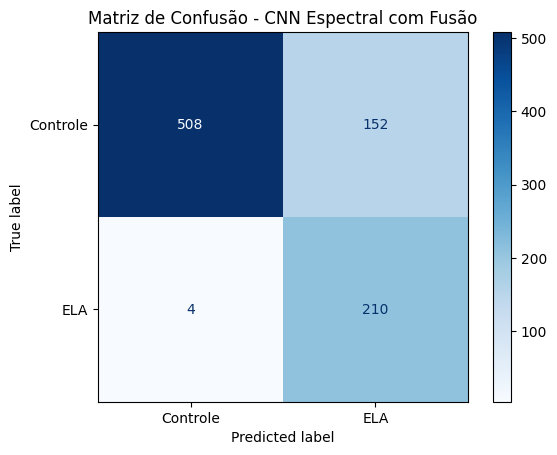

In [39]:
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    ConfusionMatrixDisplay
)

y_prob_espectral_fusao = modelo_espectral_fusao.predict(
    entradas_fusao_validacao,
    verbose=0
).ravel()

y_pred_espectral_fusao = (
    y_prob_espectral_fusao >= 0.5
).astype(int)

metricas_espectral_fusao = {
    "Acurácia": accuracy_score(
        y_validacao, y_pred_espectral_fusao
    ),
    "Acurácia balanceada": balanced_accuracy_score(
        y_validacao, y_pred_espectral_fusao
    ),
    "Precisão": precision_score(
        y_validacao, y_pred_espectral_fusao, zero_division=0
    ),
    "Sensibilidade": recall_score(
        y_validacao, y_pred_espectral_fusao, zero_division=0
    ),
    "F1-score": f1_score(
        y_validacao, y_pred_espectral_fusao, zero_division=0
    ),
    "AUROC": roc_auc_score(
        y_validacao, y_prob_espectral_fusao
    ),
    "AUPRC": average_precision_score(
        y_validacao, y_prob_espectral_fusao
    )
}

print("=== CNN ESPECTRAL COM FUSÃO — VALIDAÇÃO ===")

for nome, valor in metricas_espectral_fusao.items():
    print(f"{nome}: {valor:.4f}")

ConfusionMatrixDisplay.from_predictions(
    y_validacao,
    y_pred_espectral_fusao,
    display_labels=["Controle", "ELA"],
    cmap="Blues",
    values_format="d"
)

plt.title("Matriz de Confusão - CNN Espectral com Fusão")
plt.show()

## 9. Comparação dos modelos na validação

Os modelos são comparados com o limiar fixo de 0,5. A seleção não utiliza o conjunto de teste. Incluímos também a média das previsões por paciente, sem confundir essa agregação com validação clínica.

In [40]:
comparacao_final_validacao = pd.DataFrame({
    "CNN espectral independente": metricas_independente,
    "CNN espectral + características": metricas_espectral_fusao
}).T
print("=== COMPARAÇÃO NA VALIDAÇÃO ===")
display(comparacao_final_validacao.round(4))

resumo_por_paciente = dados_validacao[["paciente", "rotulo"]].copy()
resumo_por_paciente["CNN independente"] = prob_independente
resumo_por_paciente["CNN + características"] = y_prob_espectral_fusao
resumo_por_paciente = resumo_por_paciente.groupby("paciente", as_index=False).agg({
    "rotulo": "first", "CNN independente": "mean", "CNN + características": "mean"
})
for nome in ["CNN independente", "CNN + características"]:
    resumo_por_paciente["Previsão " + nome] = (resumo_por_paciente[nome] >= 0.5).astype(int)
print("=== RESULTADOS POR PACIENTE (VALIDAÇÃO) ===")
display(resumo_por_paciente.round(4))

=== COMPARAÇÃO NA VALIDAÇÃO ===


,Acurácia,Acurácia balanceada,Precisão,Sensibilidade,F1-score,AUROC,AUPRC
CNN espectral independente,0.9165,0.9273,0.7660,0.9486,0.8476,0.9801,0.9421
CNN espectral + características,0.8215,0.8755,0.5801,0.9813,0.7292,0.9718,0.9323


=== RESULTADOS POR PACIENTE (VALIDAÇÃO) ===


,paciente,rotulo,CNN independente,CNN + características,Previsão CNN independente,Previsão CNN + características
0,A03,1,0.8012,0.8696,1,1
1,C02,0,0.1725,0.1985,0,0
2,C09,0,0.3238,0.4350,0,0


## 10. Salvar modelos e métricas

In [41]:
from pathlib import Path
import json
pasta_saida = Path("/content/resultado_ela")
pasta_saida.mkdir(parents=True, exist_ok=True)
modelo_espectral_independente.save(str(pasta_saida / "cnn_espectral_independente.keras"))
modelo_espectral_fusao.save(str(pasta_saida / "cnn_espectral_fusao.keras"))
comparacao_final_validacao.to_csv(pasta_saida / "metricas_validacao.csv", encoding="utf-8-sig")
with open(pasta_saida / "configuracao_preprocessamento.json", "w", encoding="utf-8") as f:
    json.dump({"seed": 42, "fs_original": FS, "fator_reducao": 8,
               "media_cnn": float(media_cnn), "desvio_cnn": float(desvio_cnn),
               "caracteristicas": nomes_caracteristicas,
               "media_descritores": scaler.mean_.tolist(),
               "escala_descritores": scaler.scale_.tolist()}, f, indent=2)
print("Arquivos salvos em:", pasta_saida)

Arquivos salvos em: /content/resultado_ela


In [42]:
import shutil
from google.colab import files

arquivo_resultados = shutil.make_archive(
    "/content/resultado_ela",
    "zip",
    pasta_saida
)

print("Arquivo ZIP gerado:", arquivo_resultados)

Arquivo ZIP gerado: /content/resultado_ela.zip
